# 01. Data Understanding

1. Tải dữ liệu từ file Excel
2. Xem cấu trúc và kiểu dữ liệu của từng cột
3. Kiểm tra thống kê mô tả
4. Phát hiện missing values và outliers

In [50]:
# import các thư viện cần thiết
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [51]:
df = pd.read_excel("../data/raw/churn_prediction.xlsx")
display(df.shape)
df.head()

(5630, 20)

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,52869,0,20.0,Mobile Phone,3,7.0,E wallet,Female,4.0,4,Fashion,5,Married,3,0,26.0,5.0,16.0,NaN,229.53
1,52942,0,13.0,Computer,1,9.0,Cash on Delivery,Female,4.0,4,Fashion,3,Single,2,0,26.0,11.0,NaN,9.0,234.38
2,52972,0,16.0,Mobile Phone,3,7.0,Debit Card,Male,3.0,4,Laptop & Accessory,3,Divorced,3,0,26.0,5.0,12.0,7.0,174.07
3,53125,0,5.0,Mobile Phone,1,16.0,Debit Card,Male,3.0,4,Fashion,4,Married,3,0,26.0,2.0,2.0,9.0,231.48
4,53367,0,9.0,Mobile Phone,1,28.0,Debit Card,Female,3.0,4,Laptop & Accessory,2,Divorced,3,1,26.0,1.0,2.0,8.0,165.14


In [52]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   str    
 7   Gender                       5630 non-null   str    
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   str    
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   str    
 13  NumberOfAddress              

In [53]:
df.dtypes

CustomerID                       int64
Churn                            int64
Tenure                         float64
PreferredLoginDevice               str
CityTier                         int64
WarehouseToHome                float64
PreferredPaymentMode               str
Gender                             str
HourSpendOnApp                 float64
NumberOfDeviceRegistered         int64
PreferedOrderCat                   str
SatisfactionScore                int64
MaritalStatus                      str
NumberOfAddress                  int64
Complain                         int64
OrderAmountHikeFromlastYear    float64
CouponUsed                     float64
OrderCount                     float64
DaySinceLastOrder              float64
CashbackAmount                 float64
dtype: object

In [54]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,5630.0,52815.500000,1625.385339,50001.0,51408.25,52815.50,54222.7500,55630.00
Churn,5630.0,0.168384,0.374240,0.0,0.00,0.00,0.0000,1.00
Tenure,5366.0,10.189899,8.557241,0.0,2.00,9.00,16.0000,61.00
CityTier,5630.0,1.654707,0.915389,1.0,1.00,1.00,3.0000,3.00
WarehouseToHome,5379.0,15.639896,8.531475,5.0,9.00,14.00,20.0000,127.00
HourSpendOnApp,5375.0,2.931535,0.721926,0.0,2.00,3.00,3.0000,5.00
NumberOfDeviceRegistered,5630.0,3.688988,1.023999,1.0,3.00,4.00,4.0000,6.00
SatisfactionScore,5630.0,3.066785,1.380194,1.0,2.00,3.00,4.0000,5.00
NumberOfAddress,5630.0,4.214032,2.583586,1.0,2.00,3.00,6.0000,22.00
Complain,5630.0,0.284902,0.451408,0.0,0.00,0.00,1.0000,1.00


## Phân tích biến mục tiêu (Churn)
Churn là biến mục tiêu (target) với giá trị 0 (không rời bỏ) và 1 (rời bỏ).
Chúng ta cần kiểm tra độ cân bằng của lớp.

<Axes: xlabel='Churn', ylabel='count'>

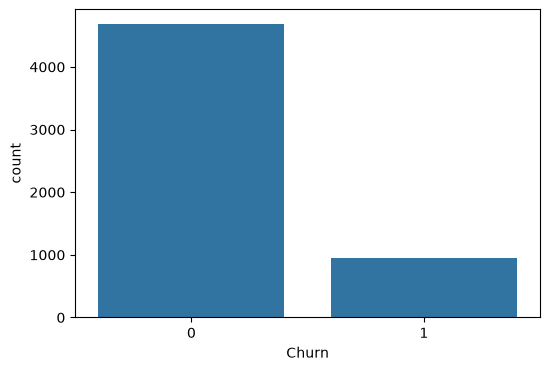

In [63]:
# Check imbalance label target 
imb_df = df.groupby('Churn')['CustomerID'].count().reset_index()
imb_df['%'] = (imb_df['CustomerID'] / imb_df['CustomerID'].sum()) * 100
imb_df

# Vẽ biểu đồ phân phối biến mục tiêu
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df)

## Kiểm tra missing values

<Axes: >

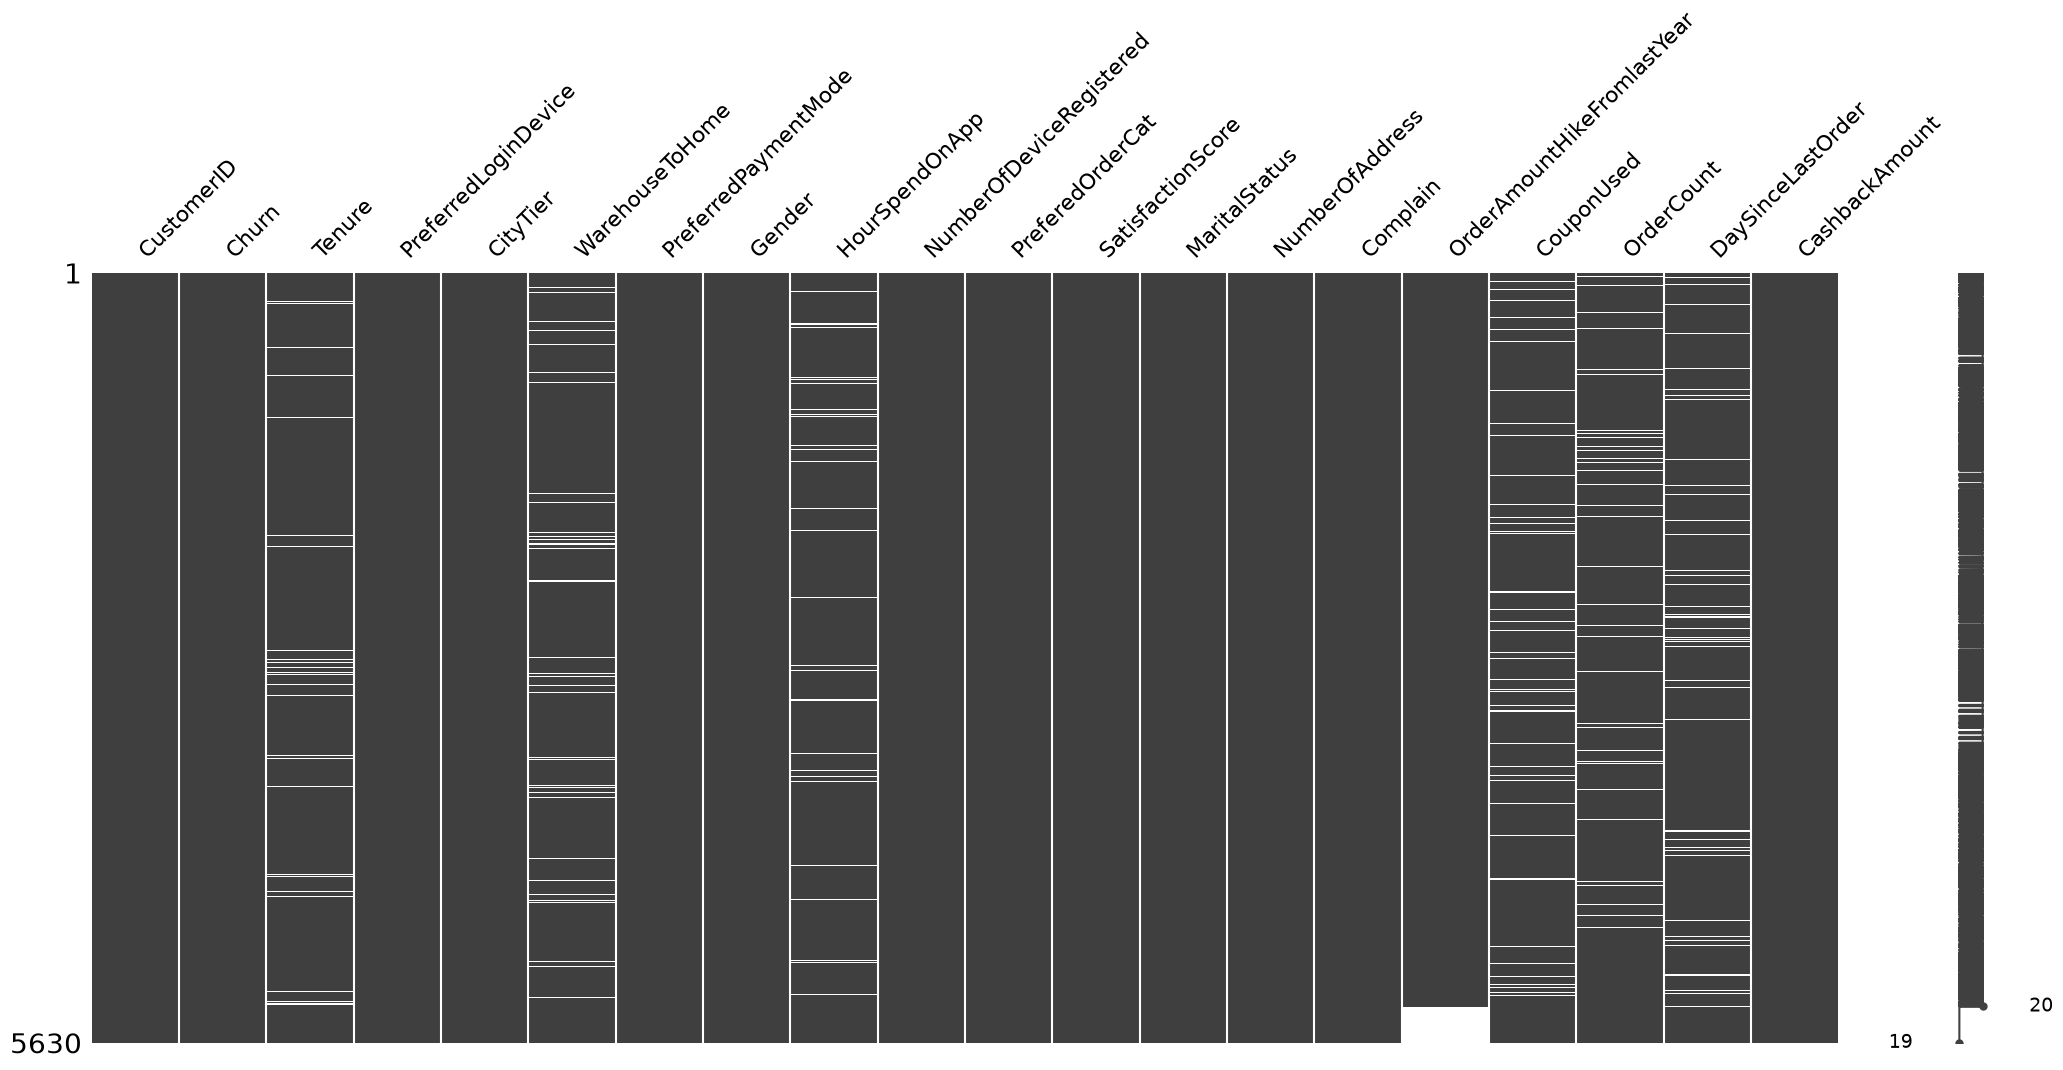

In [64]:
import missingno as msno
msno.matrix(df)

In [68]:
mising = df.isnull().sum()
missing_pct = (mising / len(df)) * 100
missing_df = pd.DataFrame({'Missing Values': mising, 'Percentage': missing_pct})
missing_df = missing_df[missing_df['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False)
missing_df

,Missing Values,Percentage
DaySinceLastOrder,307,5.452931
OrderAmountHikeFromlastYear,265,4.706927
Tenure,264,4.689165
OrderCount,258,4.582593
CouponUsed,256,4.547069
HourSpendOnApp,255,4.529307
WarehouseToHome,251,4.458259


In [75]:
duplicate_df = df.duplicated().any()
duplicate_df

np.False_

1. Dataset có 5630 dòng và 20 cột.
2. Biến mục tiêu 'Churn' phân bố không cân bằng:
   - Churn=0: 4682 KH (83.16%)
   - Churn=1: 948 KH (16.84%)
3. Tỷ lệ rời bỏ (Churn=1) khoảng 16.84%, trong khi không rời bỏ (Churn=0) chiếm khoảng 83.16%.
4. Có 7 cột chứa missing values, trong đó cao nhất là 'DaySinceLastOrder' với 307 giá trị thiếu (5.45%).
   - Các cột thiếu dữ liệu chủ yếu nằm ở các biến định lượng liên quan đến thông tin giao dịch và thời gian, như Tenure, WarehouseToHome, HourSpendOnApp, OrderAmountHikeFromlastYear, CouponUsed, OrderCount, DaySinceLastOrder.
5. Số dòng trùng lặp: 0
6. Kết luận: Dữ liệu có tính bất cân bằng ở biến mục tiêu nên cần xác định metric đánh giá phù hợp (precision/recall/F1, ROC-AUC, ...). Các biến có missing values ở mức thấp (< 6%), nên có thể xử lý bằng median/mode hoặc kỹ thuật fill missing phù hợp trước khi mô hình hóa.